# Project 2 — Sales Prediction: Forecasting Sales from Advertising Budgets

**Business objective.** A company allocates an advertising budget across three channels (**TV, Radio, Newspaper**). The goals are to (1) **forecast sales** for a given budget, (2) **measure the impact** of each channel, and (3) **recommend a more profitable allocation**.

**Data**: `Advertising.csv` — 200 campaigns. Budgets are in *thousands of dollars* and sales in *thousands of units* (as defined in the original dataset).

**Problem framing (important).**
- The file contains **no dates**, so time-series forecasting is not possible. The right tool is **regression**: “given this budget, what sales should we expect?” “Future sales” are forecasts for *planned* budgets.
- There is no “target segment” column: the **platforms** are the three channels (TV, Radio, Newspaper).

**Notebook outline**: 1. Setup · 2. Load data · 3. Clean data · 4. Univariate analysis · 5. Bivariate analysis · 6. Train/test split · 7. Baseline model and statistics · 8. Feature selection · 9. Feature engineering · 10. Model comparison · 11. Final model · 12. Impact analysis and recommendations · 13. Production deployment.

> **How to use this notebook**: run cells **one at a time** (`Shift + Enter`), reading the comments and results before moving on.

## 1. Setup

In [139]:
# --- Core libraries for data manipulation and plotting ---
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")  # keeps output readable (non-blocking warnings)

In [140]:
# --- scikit-learn: data splitting, models, and performance metrics ---
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold, cross_val_score, learning_curve, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler

In [141]:
# --- Project code (src/ directory) ---
# Reuse the EXACT production functions: what we validate here is what will be deployed.
from sales_prediction.analysis import (
    marginal_effects,
    ols_summary,
    optimize_budget,
    predict_sales,
    variance_inflation_factors,
    what_if,
)
from sales_prediction.config import load_config
from sales_prediction.features import add_engineered_features, build_pipeline

In [142]:
# --- Display settings and project constants ---
pd.set_option("display.precision", 3)         # 3 decimal places in tables
sns.set_theme(style="whitegrid")              # plot style
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42                             # random seed for reproducible results
CHANNELS = ["TV", "Radio", "Newspaper"]       # explanatory variables (budgets)
TARGET = "Sales"                              # target variable
COLORS = {"TV": "#355c9a", "Radio": "#e4572e", "Newspaper": "#8b95a1", "Sales": "#2a9d8f"}

## 2. Loading and getting to know the data

Always start by **looking** at the raw data without changing anything.

In [143]:
# Read the raw file (the notebook is in notebooks/, hence "../")
df_raw = pd.read_csv("../data/raw/Advertising.csv")
df_raw.head()  # the first 5 rows

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [144]:
# Dataset dimensions (rows, columns) and column types
print("Dimensions:", df_raw.shape)
df_raw.info()

Dimensions: (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


**Observations**: 200 rows, 5 columns, all numeric, and no apparent missing values.

The `Unnamed: 0` column looks suspicious: it is probably just a row number accidentally exported with the data. Let’s check.

In [145]:
# If the column is exactly 1, 2, 3, ... 200, it is an index with no analytical value
(df_raw["Unnamed: 0"] == np.arange(1, len(df_raw) + 1)).all()

np.True_

## 3. Data cleaning

Four checks: unnecessary columns, missing values, duplicates, and impossible values.

In [146]:
# 1) Drop the index column (unnecessary and dangerous: a model could “learn” the row number)
df = df_raw.drop(columns="Unnamed: 0").copy()
df.columns.tolist()

['TV', 'Radio', 'Newspaper', 'Sales']

In [147]:
# 2) Missing values by column
df.isna().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [148]:
# 3) Duplicate rows (counting a campaign twice would skew the statistics)
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [149]:
# 4) Impossible values: negative budgets or sales do not make sense
(df < 0).sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [150]:
# Summary statistics: count, mean, standard deviation, min, quartiles (25/50/75%), max
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.042,85.854,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.264,14.847,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.554,21.779,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.023,5.217,1.6,10.375,12.90,17.400,27.0


**How to read this table**

- **TV**: mean ≈ median (≈ 147 vs. 150) → roughly symmetric distribution, with budgets from 0.7 to 296 k$.
- **Radio**: minimum is **0** → some campaigns have no radio budget.
- **Newspaper**: mean (30.6) > median (25.8), and the maximum of 114 is far above the 75th percentile (45) → a **right-skewed distribution** with extreme values.
- **Sales**: from 1.6 to 27 (thousand units), with a mean of ≈ 14.

In [151]:
# Consistency check: does the project cleaning function (src/) produce exactly the same result?
from sales_prediction.data import clean

config = load_config()
assert clean(df_raw, config).equals(df), "Notebook cleaning differs from project cleaning"
print("OK: notebook cleaning = production cleaning")

OK: notebook cleaning = production cleaning


## 4. Univariate analysis — examining each variable separately

For each variable: distribution shape, skewness, and outliers.

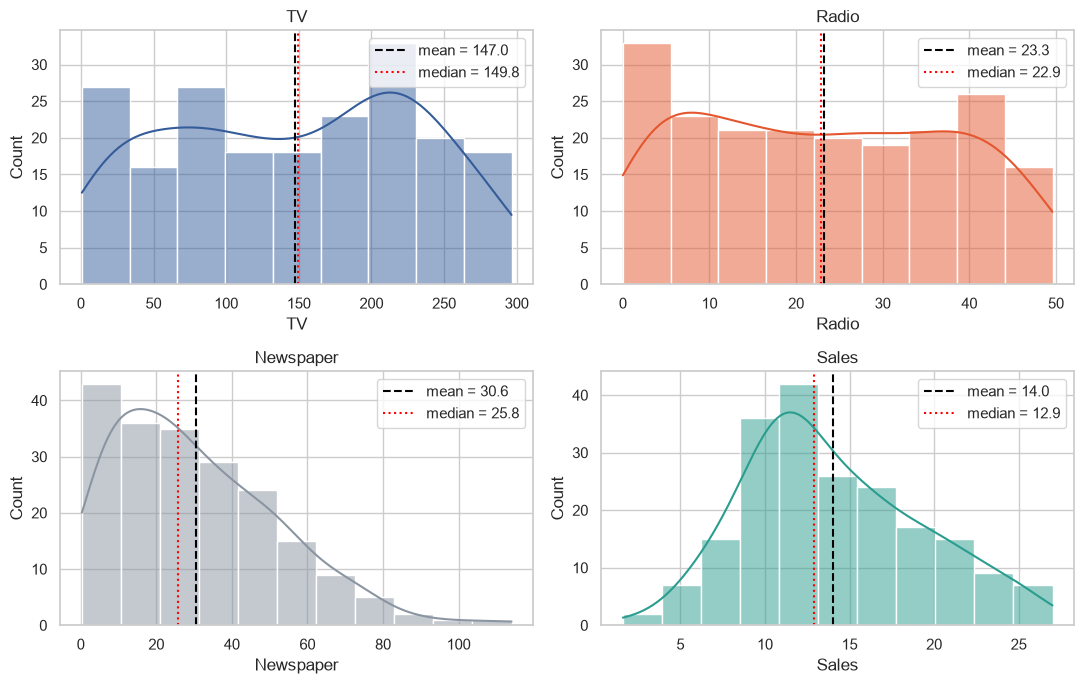

In [152]:
# Histograms + density curve (KDE). Black line = mean; red line = median.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color=COLORS[col])
    ax.axvline(df[col].mean(), color="black", linestyle="--", label=f"mean = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="red", linestyle=":", label=f"median = {df[col].median():.1f}")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [153]:
# Skewness: 0 = symmetric, > 0 = right tail, < 0 = left tail
# Kurtosis: > 0 = heavier tails than a normal distribution
df.agg(["skew", "kurt"]).T

,skew,kurt
TV,-0.070,-1.226
Radio,0.094,-1.260
Newspaper,0.895,0.650
Sales,0.408,-0.409


**Interpretation**: only **Newspaper** is notably skewed (skew ≈ 0.9). TV and Sales are close to symmetric.

Linear regression does **not** require normally distributed explanatory variables (it concerns the *residuals*, examined later), so there is no urgent need to transform Newspaper.

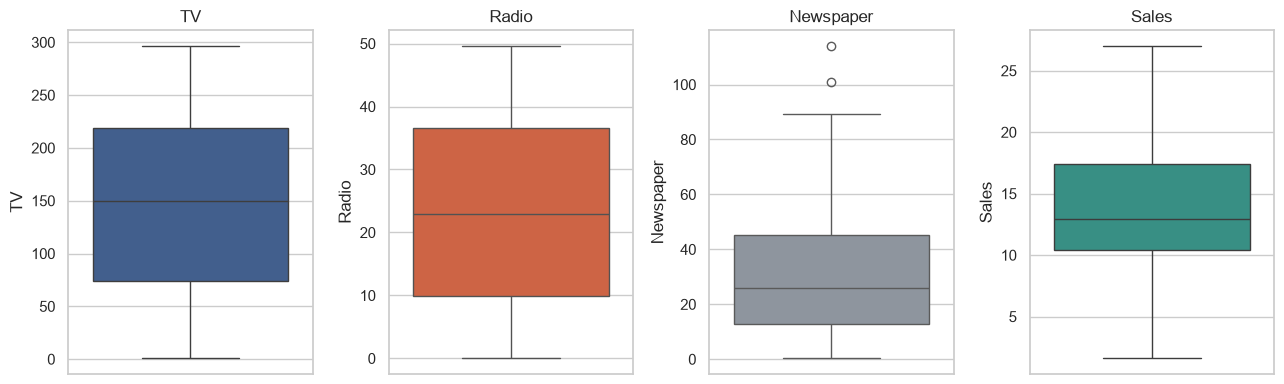

In [154]:
# Box plots: points beyond the “whiskers” are outliers (1.5 × IQR rule)
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax, color=COLORS[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [155]:
# Count outliers using the IQR (interquartile range) rule
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

df.apply(count_iqr_outliers).rename("outliers")

TV           0
Radio        0
Newspaper    2
Sales        0
Name: outliers, dtype: int64

In [156]:
# Which Newspaper campaigns are outliers?
q1, q3 = df["Newspaper"].quantile([0.25, 0.75])
df[df["Newspaper"] > q3 + 1.5 * (q3 - q1)]

,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


**Decision**: only **2 campaigns** have unusual newspaper budgets (> 93 k$). These are **real and plausible** budgets, not data-entry errors, so we **keep them**. Removing points without a business reason would discard information.

In [157]:
# Shapiro-Wilk normality test: H0 = “the variable follows a normal distribution.” p < 0.05 → reject H0.
pd.DataFrame(
    {col: {"W statistic": stats.shapiro(df[col]).statistic, "p-value": stats.shapiro(df[col]).pvalue} for col in df.columns}
).T

,W statistic,p-value
TV,0.950,1.693e-06
Radio,0.944,5.198e-07
Newspaper,0.936,1.127e-07
Sales,0.976,1.683e-03


**Interpretation**: all four p-values are much lower than 0.05 → **none of the variables is strictly normally distributed**. TV and Radio are relatively “flat” (kurtosis ≈ −1.2: budgets are fairly evenly distributed), while Newspaper is right-skewed. This is **not a problem**: regression requires normally distributed *residuals* (section 7), not explanatory variables. With 200 observations, this test is also very sensitive to small deviations.

## 5. Bivariate analysis — how is each channel related to sales?

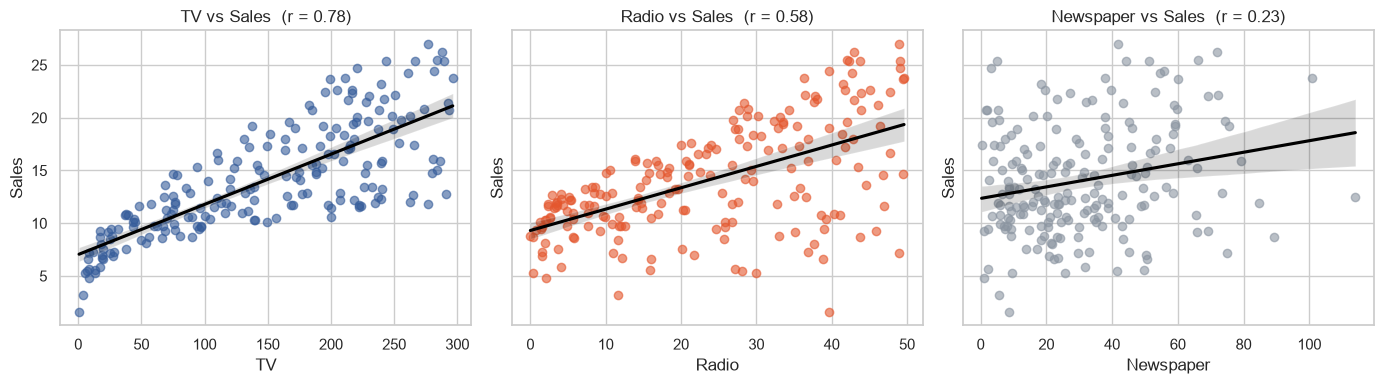

In [158]:
# Scatterplots of channel vs. sales with regression line and Pearson correlation (r)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, ch in zip(axes, CHANNELS):
    sns.regplot(data=df, x=ch, y=TARGET, ax=ax, color=COLORS[ch], scatter_kws={"alpha": 0.6}, line_kws={"color": "black"})
    ax.set_title(f"{ch} vs {TARGET}  (r = {df[ch].corr(df[TARGET]):.2f})")
plt.tight_layout()
plt.show()

In [159]:
# Pearson correlation matrix (from -1 to +1): measures the strength of the LINEAR relationship between two variables
corr = df.corr()
corr

,TV,Radio,Newspaper,Sales
TV,1.000,0.055,0.057,0.782
Radio,0.055,1.000,0.354,0.576
Newspaper,0.057,0.354,1.000,0.228
Sales,0.782,0.576,0.228,1.000


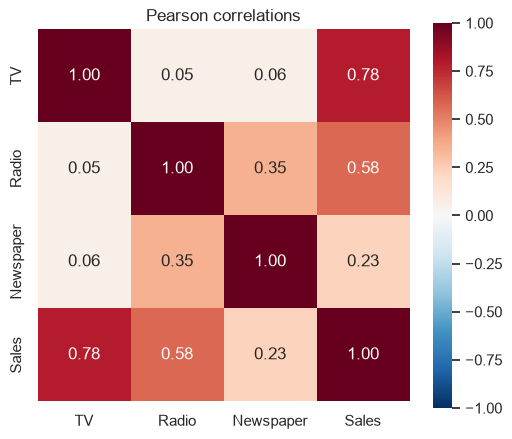

In [160]:
# Same matrix as a heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Pearson correlations")
plt.show()

**Interpretation**

- **TV ↔ Sales: 0.78** → the strongest relationship.
- **Radio ↔ Sales: 0.58** → also strong.
- **Newspaper ↔ Sales: 0.23** → weak… but **Newspaper ↔ Radio: 0.35**. Campaigns investing in newspapers also invest in radio. Newspaper may appear “useful” **only because it goes hand in hand with Radio**. Let’s test this hypothesis.

In [161]:
# Correlation robust to outliers (Spearman = correlation on ranks): does it confirm the finding?
df.corr(method="spearman")[TARGET]

TV           0.801
Radio        0.554
Newspaper    0.195
Sales        1.000
Name: Sales, dtype: float64

In [162]:
# PARTIAL CORRELATION between Newspaper and Sales, “controlling for” Radio:
# remove the part of each variable explained by Radio, then correlate the remainder.
def residuals_after(variable, control):
    return variable - LinearRegression().fit(control, variable).predict(control)

res_news = residuals_after(df["Newspaper"], df[["Radio"]])
res_sales = residuals_after(df[TARGET], df[["Radio"]])
r_partial, p_partial = stats.pearsonr(res_news, res_sales)

print(f"Raw correlation       Newspaper–Sales        : {df['Newspaper'].corr(df[TARGET]):.3f}")
print(f"Partial correlation   Newspaper–Sales | Radio: {r_partial:.3f}  (p = {p_partial:.3f})")

Raw correlation       Newspaper–Sales        : 0.228
Partial correlation   Newspaper–Sales | Radio: 0.032  (p = 0.656)


**Conclusion**: after removing the effect of Radio, the Newspaper–Sales correlation **drops to ≈ 0** and is no longer significant. This is a classic case of a **confounding variable**: *correlation does not imply causation*. Newspaper has no measurable independent effect; it is simply associated with Radio.

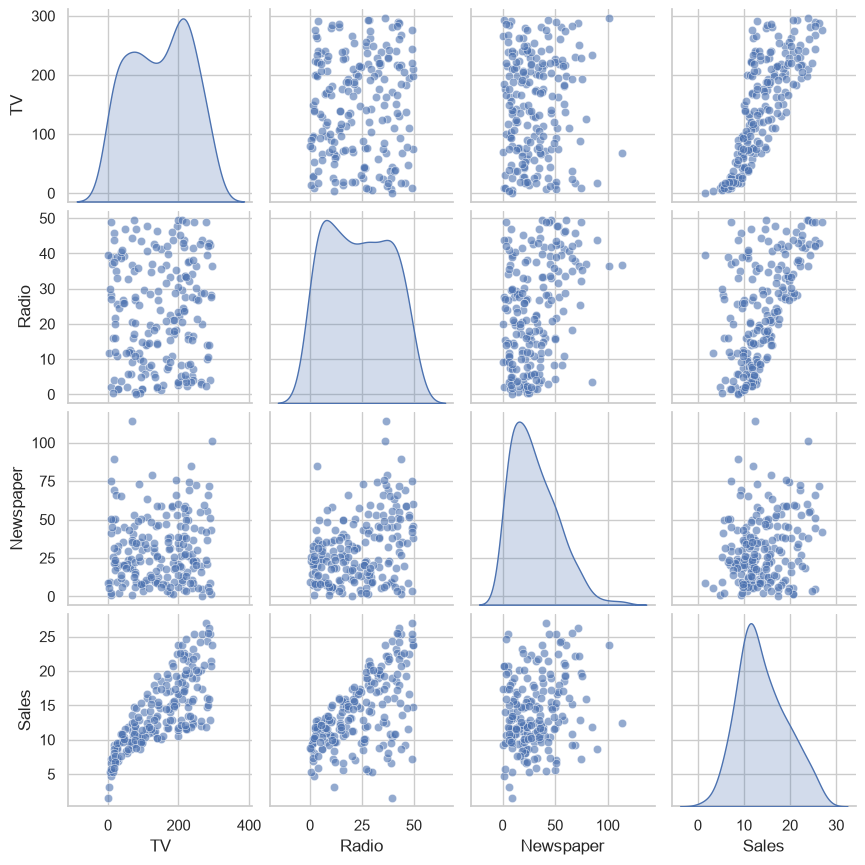

In [163]:
# Overview of all pairs of variables
sns.pairplot(df, diag_kind="kde", height=2.2, plot_kws={"alpha": 0.6})
plt.show()

In [164]:
# MULTICOLLINEARITY: VIF (Variance Inflation Factor). VIF ≈ 1 = variable independent of the others; > 5 = a problem.
variance_inflation_factors(df[CHANNELS])

TV           1.005
Radio        1.145
Newspaper    1.145
Name: VIF, dtype: float64

**Interpretation**: all VIFs are close to 1 → the three budgets have little redundancy, so regression coefficients should be **stable and interpretable**.

### A hint of synergy

The `TV vs. Sales` scatterplot is shaped like a **funnel**: sales vary considerably at the same TV budget. Does Radio explain this variation?

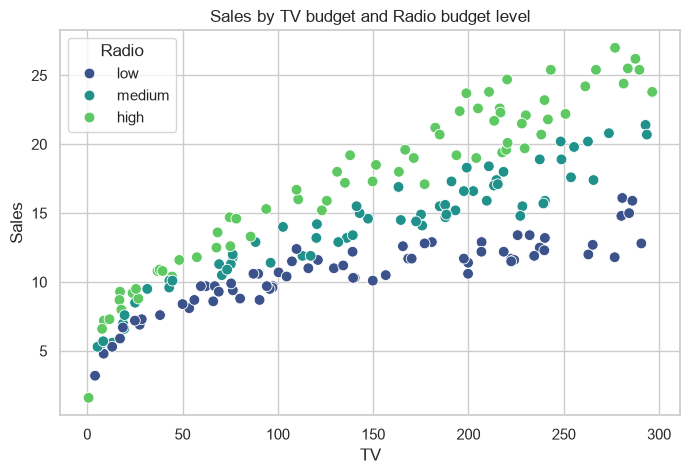

In [165]:
# Color each campaign by its Radio budget tercile (low / medium / high)
radio_level = pd.qcut(df["Radio"], 3, labels=["low", "medium", "high"])

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="TV", y=TARGET, hue=radio_level, palette="viridis", s=60)
plt.title("Sales by TV budget and Radio budget level")
plt.show()

In [166]:
# Average sales for each combination of TV and Radio levels
labels = ["low", "medium", "high"]
levels = pd.DataFrame(
    {
        "TV": pd.qcut(df["TV"], 3, labels=labels),
        "Radio": pd.qcut(df["Radio"], 3, labels=labels),
        "Sales": df[TARGET],
    }
)
pivot = levels.pivot_table(index="TV", columns="Radio", values="Sales", aggfunc="mean", observed=True)
pivot

Radio,low,medium,high
TV,,,
low,8.172,9.042,10.396
medium,11.213,14.564,18.606
high,12.995,18.010,22.858


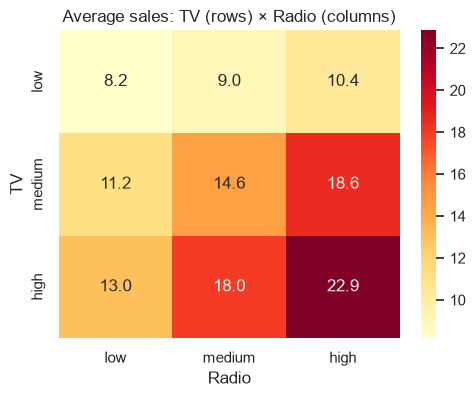

In [167]:
plt.figure(figsize=(5.5, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Average sales: TV (rows) × Radio (columns)")
plt.show()

**Interpretation (important for what follows)**: moving from low to high Radio spend increases sales **much more when the TV budget is high**. The effects do not simply **add**; they **multiply**: this is a **synergy effect** (TV × Radio). A simple linear model (sum of effects) will miss it. Keep hypothesis **H1** in mind for section 9.

## 6. Train/test split

We set aside 20% of campaigns (**test set**) **before any modeling**. The model will never see them during training; they measure its ability to predict genuinely new situations. Splitting *after* exploring relationships or selecting variables based on the test set would cause **data leakage**.

In [168]:
X = df[CHANNELS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training: {len(X_train)} campaigns | Test: {len(X_test)} campagnes")

Training: 160 campaigns | Test: 40 campagnes


In [169]:
# Are the two sets similar? (otherwise train/test comparison would not make sense)
comparison = pd.concat(
    {"train": X_train.assign(Sales=y_train).mean(), "test": X_test.assign(Sales=y_test).mean()}, axis=1
)
comparison

,train,test
TV,150.019,135.135
Radio,22.876,24.818
Newspaper,29.946,32.987
Sales,14.100,13.713


In [170]:
# --- Measurement tools reused throughout the notebook ---
def metrics(y_true, y_pred):
    # R²: share of sales variability explained (1 = perfect) | RMSE / MAE: average error in thousand units
    return {
        "R²": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


def fit_and_score(model, name):
    # Train on the training set; score on BOTH train and test (a large gap signals overfitting)
    model.fit(X_train, y_train)
    scores = {}
    for label, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        for metric, value in metrics(ys, model.predict(Xs)).items():
            scores[f"{metric} {label}"] = value
    return pd.Series(scores, name=name)

In [171]:
# Repeated cross-validation: 5 folds × 5 repeats = 25 evaluations on the training set.
# More reliable than a single split with a small dataset (160 rows here).
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)


def cv_scores(model, name, X_=None):
    X_ = X_train if X_ is None else X_
    r2 = cross_val_score(model, X_, y_train, cv=cv, scoring="r2")
    rmse = -cross_val_score(model, X_, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    return pd.Series(
        {"Mean CV R²": r2.mean(), "CV R² standard deviation": r2.std(), "Mean CV RMSE": rmse.mean()}, name=name
    )

## 7. Baseline model: multiple linear regression

**Baseline model**: `Sales = b0 + b1·TV + b2·Radio + b3·Newspaper`. Any more complex model must **beat it** to justify its added complexity.

In [172]:
baseline = LinearRegression()
fit_and_score(baseline, "Baseline (TV, Radio, Newspaper)").to_frame()

,"Baseline (TV, Radio, Newspaper)"
R² train,0.896
RMSE train,1.645
MAE train,1.198
R² test,0.899
RMSE test,1.782
MAE test,1.461


In [173]:
# Coefficients: additional sales (thousand units) for +1 k$ on a channel, holding others constant
pd.concat([pd.Series({"intercept": baseline.intercept_}), pd.Series(baseline.coef_, index=CHANNELS)]).rename("coefficient")

intercept    2.979
TV           0.045
Radio        0.189
Newspaper    0.003
Name: coefficient, dtype: float64

### Statistical inference: are the coefficients reliable?

`scikit-learn` provides coefficients but not their **statistical significance**. Our `ols_summary` function (in `src/analysis.py`) calculates:

- **std_err**: uncertainty in the coefficient; **t** = coefficient / std_err;
- **p_value**: probability of observing a coefficient this extreme *if the true effect were zero* (**p < 0.05** → statistically significant effect);
- **ci_low / ci_high**: 95% confidence interval (if it contains 0, the effect cannot be distinguished from zero).

In [174]:
table, summary = ols_summary(X_train, y_train)
table

,coef,std_err,t,p_value,ci_low,ci_high
intercept,2.979,0.354,8.427,2.202e-14,2.281,3.677
TV,0.045,0.002,28.544,8.166e-64,0.042,0.048
Radio,0.189,0.010,19.518,1.016e-43,0.170,0.208
Newspaper,0.003,0.007,0.392,6.958e-01,-0.011,0.017


In [175]:
# Overall statistics: R², adjusted R² (penalizes the number of variables), F-test (does the model explain more than “the mean”?)
pd.Series(summary)

n            1.600e+02
r2           8.957e-01
adj_r2       8.937e-01
f_stat       4.466e+02
f_p_value    2.529e-76
dtype: float64

**Interpretation**: TV and Radio are highly significant (p ≈ 0). **Newspaper has a p-value far above 0.05 and a confidence interval containing 0**: its effect cannot be distinguished from zero, confirming the partial correlation from section 5.

### Residual diagnostics

A residual = actual sales − predicted sales. If the model is well specified, residuals should look like **noise**: centered around 0, with no structure, approximately normal, and with constant variance.

In [176]:
def residual_diagnostics(model, X_, y_, title):
    fitted = model.predict(X_)
    resid = y_ - fitted

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(fitted, resid, alpha=0.6)
    axes[0].axhline(0, color="red")
    axes[0].set(title=f"{title}: residuals vs. predictions", xlabel="Predicted sales", ylabel="Residual")
    stats.probplot(resid, dist="norm", plot=axes[1])  # points on the line indicate normal residuals
    axes[1].set_title("QQ plot (normality)")
    sns.histplot(resid, kde=True, ax=axes[2], color="#2a9d8f")
    axes[2].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

    shapiro = stats.shapiro(resid)
    rho = stats.spearmanr(fitted, np.abs(resid))
    print(f"Shapiro-Wilk: W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.4f}   (p > 0.05 → residuals are consistent with a normal distribution)")
    print(f"Spearman |residuals| vs. predictions: rho = {rho.statistic:.3f}, p = {rho.pvalue:.4f}   (p < 0.05 → non-constant variance)")

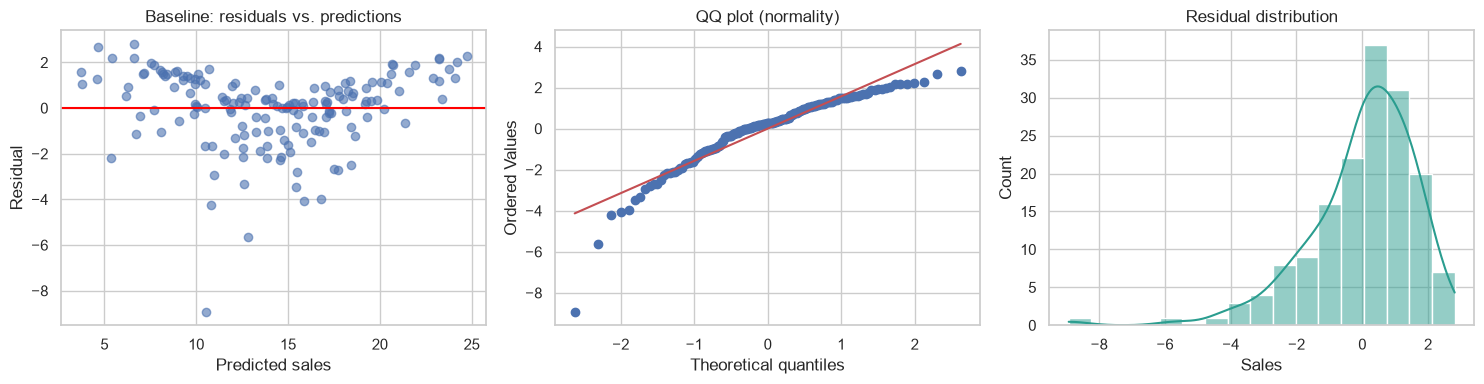

Shapiro-Wilk: W = 0.896, p = 0.0000   (p > 0.05 → residuals are consistent with a normal distribution)
Spearman |residuals| vs. predictions: rho = -0.114, p = 0.1502   (p < 0.05 → non-constant variance)


In [177]:
residual_diagnostics(baseline, X_train, y_train, "Baseline")

**Interpretation**: the residuals form a **U-shaped curve** (the model overestimates at the extremes and underestimates in the middle), and the QQ plot deviates from the line. The baseline model **misses a pattern**: the relationship is not purely linear and additive. This supports the synergy hint (H1) and suggests **diminishing returns** (H2), revisited in section 9.

## 8. Feature selection — should we keep Newspaper?

We combine **three independent pieces of evidence** before deciding.

**Evidence 1: statistical significance** (section 7).

In [178]:
table["p_value"].rename("p-value").to_frame()

,p-value
intercept,2.202e-14
TV,8.166e-64
Radio,1.016e-43
Newspaper,6.958e-01


**Evidence 2: predictive performance** — does the model improve when Newspaper is included? (cross-validation)

In [179]:
def keep(*names):
    # Linear model using only the specified columns
    return make_pipeline(FunctionTransformer(lambda d: d[list(names)]), LinearRegression())


pd.DataFrame(
    [
        cv_scores(keep("TV", "Radio", "Newspaper"), "TV + Radio + Newspaper"),
        cv_scores(keep("TV", "Radio"), "TV + Radio"),
        cv_scores(keep("TV"), "TV only"),
    ]
)

,Mean CV R²,CV R² standard deviation,Mean CV RMSE
TV + Radio + Newspaper,0.882,0.052,1.664
TV + Radio,0.884,0.052,1.649
TV only,0.551,0.125,3.285


**Evidence 3: permutation importance** — how much does R² fall if we *randomly shuffle* a column in the test set? (the larger the drop, the more important the variable)

In [180]:
perm = permutation_importance(baseline, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
importance = pd.DataFrame({"R² drop": perm.importances_mean, "standard deviation": perm.importances_std}, index=CHANNELS)
importance.sort_values("R² drop", ascending=False)

,R² drop,standard deviation
TV,1.142,0.168
Radio,0.450,0.061
Newspaper,-0.001,0.001


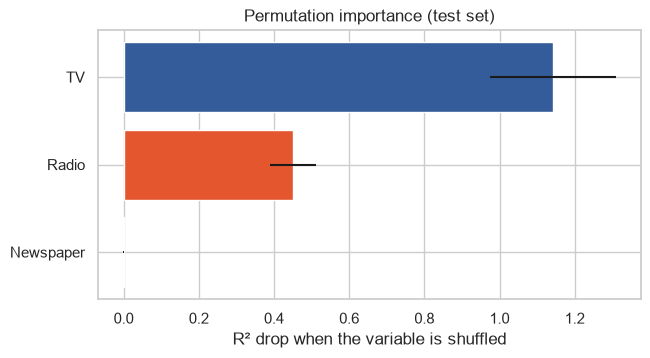

In [181]:
ordered = importance.sort_values("R² drop")
plt.figure(figsize=(7, 3.5))
plt.barh(ordered.index, ordered["R² drop"], xerr=ordered["standard deviation"], color=[COLORS[c] for c in ordered.index])
plt.xlabel("R² drop when the variable is shuffled")
plt.title("Permutation importance (test set)")
plt.show()

### Decision

| Evidence | Result for Newspaper |
|---|---|
| p-value | ≫ 0.05 → effect is not significant |
| Cross-validation | no improvement (same R² with or without it) |
| Permutation importance | ≈ 0 |
| Partial correlation | ≈ 0 after controlling for Radio |

**Newspaper is removed from the model.** This is also a **business finding**: newspaper spend has no measurable effect on sales in this dataset. (The selection is specified in `configs/config.yaml` → `features.selected`.)

## 9. Feature engineering

Two hypotheses emerged from the exploration:

- **H1 — synergy**: the effect of TV depends on the Radio budget → add **TV × Radio**.
- **H2 — diminishing returns**: each additional TV dollar generates less than the previous one → add **TV²** (a negative coefficient would indicate saturation).

We test them **one at a time** using cross-validation and production function `add_engineered_features`.

In [182]:
# Preview of features created by the production function
add_engineered_features(X_train, selected=["TV", "Radio"], interaction=True, quadratic=["TV"]).head()

,TV,Radio,TV_x_Radio,TV_sq
79,116.0,7.7,893.20,13456.00
197,177.0,9.3,1646.10,31329.00
38,43.1,26.7,1150.77,1857.61
24,62.3,12.6,784.98,3881.29
122,224.0,2.4,537.60,50176.00


In [183]:
def engineered(selected, interaction, quadratic):
    return make_pipeline(
        FunctionTransformer(
            add_engineered_features,
            kw_args={"selected": selected, "interaction": interaction, "quadratic": quadratic},
        ),
        LinearRegression(),
    )


candidates = {
    "M0 · TV + Radio": engineered(["TV", "Radio"], False, []),
    "M1 · + TV×Radio (H1)": engineered(["TV", "Radio"], True, []),
    "M2 · + TV² (H2)": engineered(["TV", "Radio"], True, ["TV"]),
    "M3 · + Radio²": engineered(["TV", "Radio"], True, ["TV", "Radio"]),
    "M4 · M2 + Newspaper": engineered(CHANNELS, True, ["TV"]),
}
results_fe = pd.DataFrame([cv_scores(model, name) for name, model in candidates.items()])
results_fe

,Mean CV R²,CV R² standard deviation,Mean CV RMSE
M0 · TV + Radio,0.884,0.052,1.649
M1 · + TV×Radio (H1),0.962,0.023,0.943
M2 · + TV² (H2),0.983,0.014,0.613
M3 · + Radio²,0.983,0.014,0.614
M4 · M2 + Newspaper,0.981,0.013,0.651


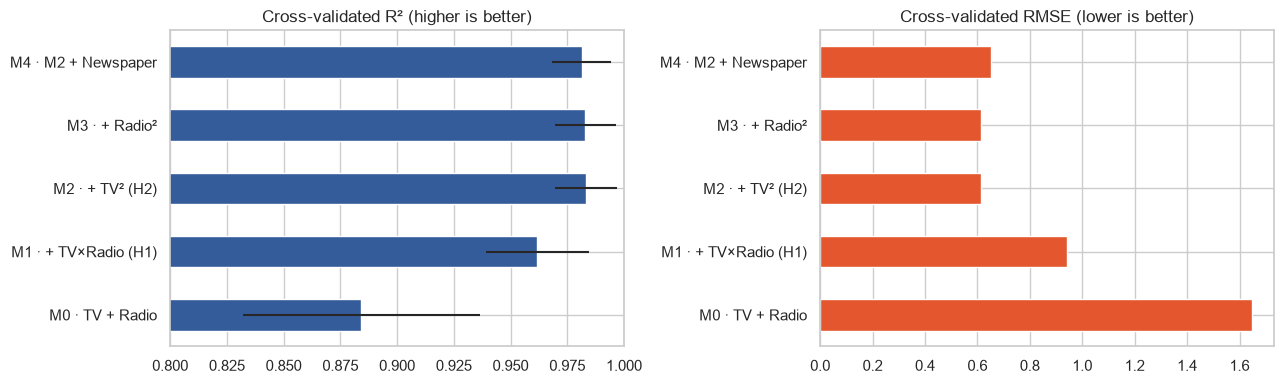

In [184]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results_fe["Mean CV R²"].plot.barh(ax=axes[0], color="#355c9a", xerr=results_fe["CV R² standard deviation"])
axes[0].set(title="Cross-validated R² (higher is better)", xlim=(0.8, 1.0))
results_fe["Mean CV RMSE"].plot.barh(ax=axes[1], color="#e4572e")
axes[1].set(title="Cross-validated RMSE (lower is better)")
plt.tight_layout()
plt.show()

**Interpretation**

- **M1** (synergy) increases R² from about 0.88 to about 0.96: H1 is **confirmed**, with the largest improvement.
- **M2** (TV²) provides another clear improvement: H2 is **confirmed** (diminishing returns for TV).
- **M3** (Radio²) does not improve performance: no measurable saturation for Radio over the observed range.
- **M4** (adding Newspaper back) adds nothing: section 8’s feature selection is **confirmed**.

We select **M2**: `Sales = b0 + b1·TV + b2·Radio + b3·TV×Radio + b4·TV²`. Let’s check its coefficients.

In [185]:
X_train_fe = add_engineered_features(X_train, ["TV", "Radio"], interaction=True, quadratic=["TV"])
table_fe, summary_fe = ols_summary(X_train_fe, y_train)
table_fe

,coef,std_err,t,p_value,ci_low,ci_high
intercept,5.076e+00,2.155e-01,23.555,4.409e-53,4.651e+00,5.502e+00
TV,5.151e-02,2.484e-03,20.737,1.469e-46,4.660e-02,5.641e-02
Radio,3.674e-02,6.671e-03,5.508,1.475e-07,2.357e-02,4.992e-02
TV_x_Radio,1.065e-03,3.880e-05,27.445,2.176e-61,9.882e-04,1.142e-03
TV_sq,-1.105e-04,7.713e-06,-14.327,3.462e-30,-1.257e-04,-9.527e-05


In [186]:
pd.Series(summary_fe)

n             1.600e+02
r2            9.852e-01
adj_r2        9.848e-01
f_stat        2.579e+03
f_p_value    1.214e-140
dtype: float64

**Interpreting the coefficients**

- `TV_x_Radio` **> 0** and significant: **each dollar spent on Radio makes TV more effective** (and vice versa) → synergy.
- `TV_sq` **< 0** and significant: TV’s marginal contribution **decreases** as its budget grows → saturation.
- `TV` and `Radio`: baseline effects; **the actual effect of a channel depends on the levels of the others** (quantified in section 12).

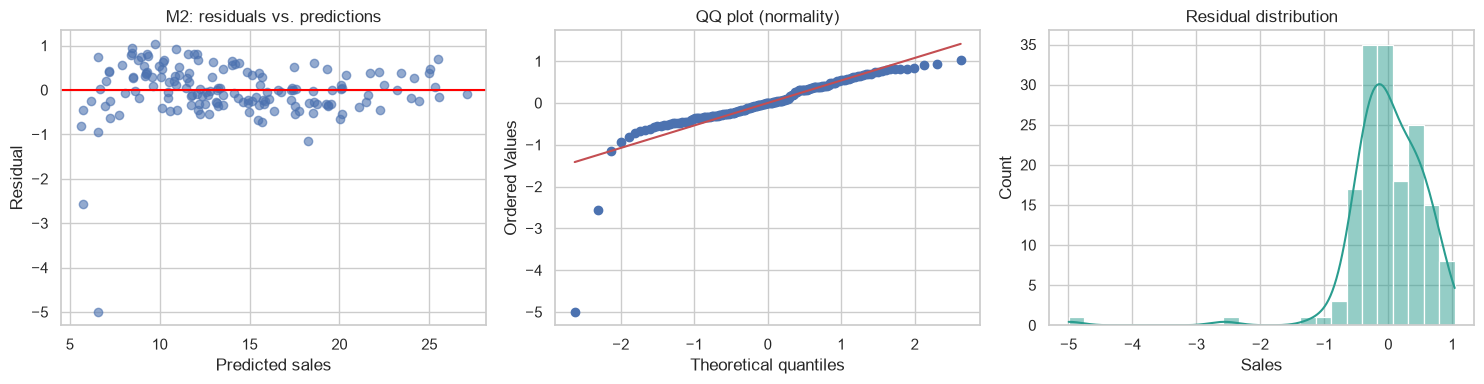

Shapiro-Wilk: W = 0.749, p = 0.0000   (p > 0.05 → residuals are consistent with a normal distribution)
Spearman |residuals| vs. predictions: rho = -0.266, p = 0.0007   (p < 0.05 → non-constant variance)


In [187]:
# Do the residuals now look like noise?
m2 = candidates["M2 · + TV² (H2)"].fit(X_train, y_train)
residual_diagnostics(m2, X_train, y_train, "M2")

**An honest assessment**

- ✅ The **U-shaped curve has disappeared** and residuals are about **5 times smaller** (scale ±1 vs. ±8 for the baseline): the model now captures the data structure.
- ⚠️ The Shapiro–Wilk test is still rejected and variance is not perfectly constant. The plot shows why: **two campaigns** (residuals of −5 and −2.6) are far below the others. Let’s examine them.

In [188]:
# The model's 3 largest overestimates on the training set
residuals_m2 = y_train - m2.predict(X_train)
worst = residuals_m2.sort_values().head(3).index
X_train.loc[worst].assign(Sales=y_train[worst], predicted=m2.predict(X_train.loc[worst]), residual=residuals_m2[worst])

,TV,Radio,Newspaper,Sales,predicted,residual
130,0.7,39.6,8.7,1.6,6.597,-4.997
155,4.1,11.6,5.7,3.2,5.763,-2.563
41,177.0,33.4,38.7,17.1,18.254,-1.154


**Explanation**: these two campaigns had **near-zero TV budgets** (0.7 and 4.1 k$). The model predicts about 6 thousand units, while actual sales were 1.6 and 3.2. The quadratic curve does not fall low enough when TV spend is almost zero: **the model is less reliable for very low TV budgets** (2 of 160 campaigns). These are real observations, so we **keep them**; let’s check that the results do not depend on them.

In [189]:
# Robustness test: retrain WITHOUT these 2 campaigns, then compare coefficients and test R²
mask = ~X_train.index.isin(worst[:2])
m2_robust = engineered(["TV", "Radio"], True, ["TV"]).fit(X_train[mask], y_train[mask])

pd.DataFrame(
    {
        "with all campaigns": [*m2.named_steps["linearregression"].coef_, m2.score(X_test, y_test)],
        "without the 2 outliers": [*m2_robust.named_steps["linearregression"].coef_, m2_robust.score(X_test, y_test)],
    },
    index=["TV", "Radio", "TV×Radio", "TV²", "Test R²"],
)

,with all campaigns,without the 2 outliers
TV,5.151e-02,4.614e-02
Radio,3.674e-02,4.316e-02
TV×Radio,1.065e-03,1.031e-03
TV²,-1.105e-04,-9.324e-05
Test R²,9.885e-01,9.874e-01


**Conclusion**: coefficients change modestly and **test R² remains almost identical**: the model is **stable**, and predictions do not depend on these two points. OLS p-values and confidence intervals assume normal residuals, so they are **indicative** (synergy and saturation remain highly significant, with tiny p-values). For this reason, the API does not return a prediction interval.

## 10. Comparing with more complex models

In [190]:
challengers = {
    "M2 linear regression (selected)": candidates["M2 · + TV² (H2)"],
    "Degree-2 polynomial + Ridge": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 20))),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
comparison_models = pd.DataFrame([cv_scores(model, name) for name, model in challengers.items()])
comparison_models

,Mean CV R²,CV R² standard deviation,Mean CV RMSE
M2 linear regression (selected),0.983,0.014,0.613
Degree-2 polynomial + Ridge,0.981,0.013,0.658
Random Forest,0.969,0.012,0.863
Gradient Boosting,0.970,0.012,0.845


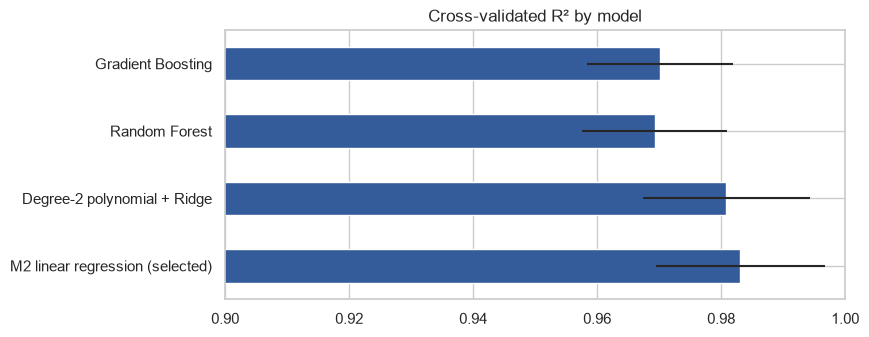

In [191]:
comparison_models["Mean CV R²"].plot.barh(figsize=(8, 3.5), color="#355c9a", xerr=comparison_models["CV R² standard deviation"])
plt.xlim(0.9, 1.0)
plt.title("Cross-validated R² by model")
plt.show()

### Final model choice: M2 linear regression

M2 performs **as well as** Polynomial + Ridge and **better than** tree-based models (RMSE ≈ 0.61 vs. ≈ 0.85). With 200 observations and a smooth relationship, complex models add little. Other criteria:

1. **Interpretable**: each coefficient has business meaning (essential for advising a marketing director).
2. **Reasonable extrapolation**: a Random Forest returns a *constant* beyond the maximum budget it has seen; the polynomial retains a meaningful shape.
3. **Simple and fast**: 5 coefficients, instant training, and a model only a few KB in size.
4. **Reliable for simulations** (“what if I increase TV spend by 10%?”) because its response is smooth and predictable.

## 11. Final model: honest training and evaluation

Here we use the **production pipeline** (`build_pipeline`, configured by `configs/config.yaml`): the same code and feature selection.

In [192]:
final_model = build_pipeline(config).fit(X_train, y_train)
fit_and_score(final_model, "Final model").to_frame()

,Final model
R² train,0.985
RMSE train,0.620
MAE train,0.399
R² test,0.989
RMSE test,0.602
MAE test,0.497


**Interpretation**: scores on the **unseen test set** are close to training scores → no overfitting. R² indicates that the model explains about 98–99% of sales variability; RMSE/MAE give the typical error in thousands of units.

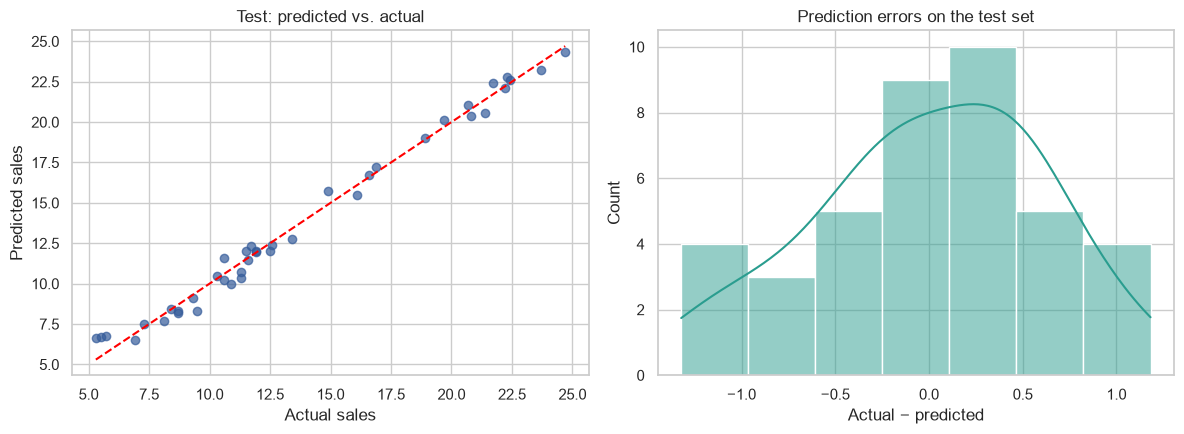

In [193]:
# Predictions vs. actual values on the test set: points should follow the diagonal
pred_test = final_model.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred_test, alpha=0.7, color="#355c9a")
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[0].plot(lims, lims, color="red", linestyle="--")
axes[0].set(title="Test: predicted vs. actual", xlabel="Actual sales", ylabel="Predicted sales")
sns.histplot(y_test - pred_test, kde=True, ax=axes[1], color="#2a9d8f")
axes[1].set(title="Prediction errors on the test set", xlabel="Actual − predicted")
plt.tight_layout()
plt.show()

In [194]:
# Error analysis: where does the model make the largest mistakes?
errors = X_test.assign(actual=y_test, predicted=pred_test)
errors["error"] = errors["predicted"] - errors["actual"]
errors["error %"] = errors["error"] / errors["actual"] * 100
errors.reindex(errors["error"].abs().sort_values(ascending=False).index).head(5)

,TV,Radio,Newspaper,actual,predicted,error,error %
78,5.4,29.9,9.4,5.3,6.622,1.322,24.940
56,7.3,28.1,41.4,5.5,6.697,1.197,21.770
66,31.5,24.6,2.2,9.5,8.318,-1.182,-12.440
132,8.4,27.2,2.1,5.7,6.744,1.044,18.314
9,199.8,2.6,21.2,10.6,11.605,1.005,9.480


**Interpretation**: the largest **relative** errors (up to ≈ 25%) occur for campaigns with **low sales** (≈ 5 thousand units): an error of 1.3 thousand is substantial when the total is small. In absolute terms, no test-set error exceeds ≈ 1.3 thousand units.

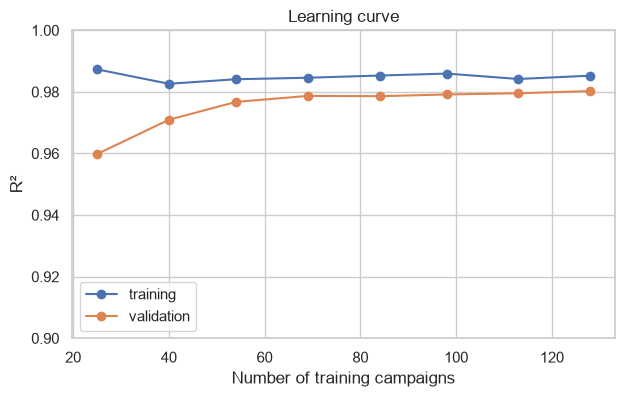

In [195]:
# Learning curve: would the model benefit from more data?
sizes, train_scores, val_scores = learning_curve(
    build_pipeline(config), X_train, y_train, cv=5, train_sizes=np.linspace(0.2, 1.0, 8), scoring="r2", random_state=RANDOM_STATE, shuffle=True
)
plt.figure(figsize=(7, 4))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="training")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="validation")
plt.xlabel("Number of training campaigns")
plt.ylabel("R²")
plt.ylim(0.9, 1.0)
plt.legend()
plt.title("Learning curve")
plt.show()

**Interpretation**: the validation curve nearly meets the training curve and stabilizes around 70 campaigns at a high level (≈ 0.98) → the model is **well sized** (neither underfitting nor overfitting), and more data would bring only marginal improvement.

## 12. Advertising impact analysis and recommendations

This is the heart of the project: **what happens when we change the budgets?** We start with an “average” campaign (average budgets in the dataset) and run simulations.

In [196]:
# Reference campaign = average budgets
base = X.mean().to_dict()
print("Average budgets (k$):", {k: round(v, 1) for k, v in base.items()})
print(f"Predicted sales: {predict_sales(final_model, base):.2f} thousand units")

Average budgets (k$): {'TV': 147.0, 'Radio': 23.3, 'Newspaper': 30.6}
Predicted sales: 14.76 thousand units


### 12.1 Marginal effect: what does an additional $1,000 on each channel generate?

In [197]:
effects = marginal_effects(final_model, base, step=1.0)  # additional sales for +1 k$, holding other channels constant
impact = pd.DataFrame(
    {
        "Additional sales (thousand units) per +1 k$": effects,
        "Additional units sold per +$1,000": {k: round(v * 1000) for k, v in effects.items()},
    }
)
impact

,Additional sales (thousand units) per +1 k$,"Additional units sold per +$1,000"
TV,0.044,44
Radio,0.193,193
Newspaper,0.000,0


**Interpretation**: at the average budget, **an additional $1,000 on Radio generates about 4 times more units than $1,000 on TV**, and Newspaper generates **0**. Marginal effects depend on budget levels (synergy and saturation), as shown in the following charts.

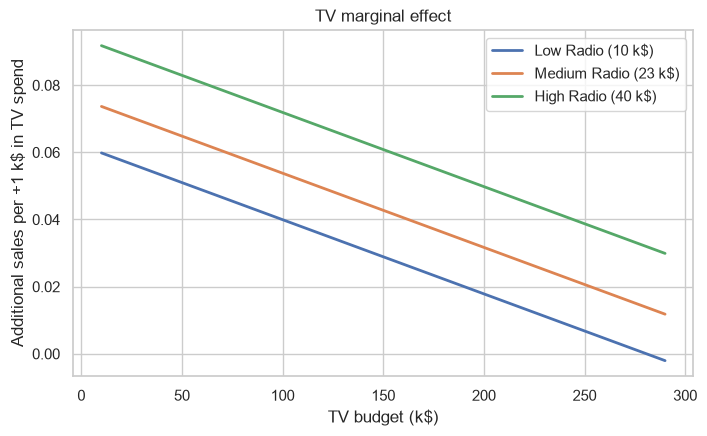

In [198]:
# TV marginal effect by TV budget, at three Radio levels: diminishing returns + synergy
tv_grid = np.arange(10, 291, 10)
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, radio in {"Low Radio (10 k$)": 10, "Medium Radio (23 k$)": 23, "High Radio (40 k$)": 40}.items():
    marginal_tv = [marginal_effects(final_model, {"TV": t, "Radio": radio, "Newspaper": base["Newspaper"]})["TV"] for t in tv_grid]
    ax.plot(tv_grid, marginal_tv, label=label, linewidth=2)
ax.set(xlabel="TV budget (k$)", ylabel="Additional sales per +1 k$ in TV spend", title="TV marginal effect")
ax.legend()
plt.show()

**Interpretation**: each curve **slopes downward** (diminishing returns: the more spent on TV, the less the next dollar generates), and the curves shift **upward** as Radio spend increases (synergy: more Radio makes TV more effective).

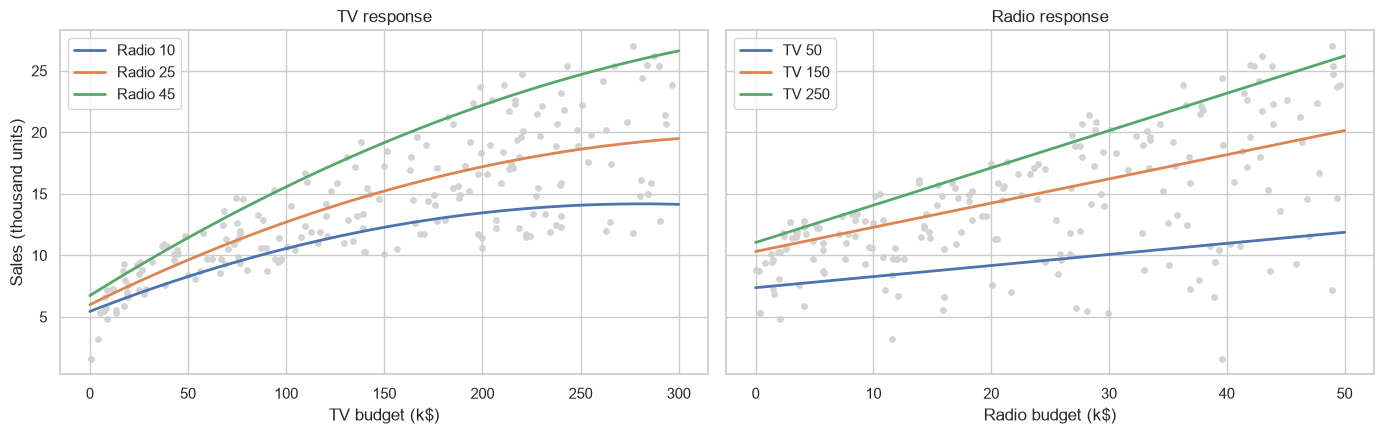

In [199]:
# Response curves: sales by TV budget at three Radio levels (gray points = actual campaigns)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

grid_tv = pd.DataFrame({"TV": np.linspace(0, 300, 100)})
for label, radio in {"Radio 10": 10, "Radio 25": 25, "Radio 45": 45}.items():
    curve = final_model.predict(grid_tv.assign(Radio=radio, Newspaper=base["Newspaper"]))
    axes[0].plot(grid_tv["TV"], curve, linewidth=2, label=label)
axes[0].scatter(df["TV"], df[TARGET], color="lightgray", s=15, zorder=0)
axes[0].set(xlabel="TV budget (k$)", ylabel="Sales (thousand units)", title="TV response")
axes[0].legend()

grid_radio = pd.DataFrame({"Radio": np.linspace(0, 50, 100)})
for label, tv in {"TV 50": 50, "TV 150": 150, "TV 250": 250}.items():
    curve = final_model.predict(grid_radio.assign(TV=tv, Newspaper=base["Newspaper"]))
    axes[1].plot(grid_radio["Radio"], curve, linewidth=2, label=label)
axes[1].scatter(df["Radio"], df[TARGET], color="lightgray", s=15, zorder=0)
axes[1].set(xlabel="Radio budget (k$)", title="Radio response")
axes[1].legend()
plt.tight_layout()
plt.show()

### 12.2 “What if…?” scenarios

In [200]:
# Increase one or more channel budgets by 10%, holding the others unchanged
scenarios = {
    "TV +10%": {"TV": 10},
    "Radio +10%": {"Radio": 10},
    "Newspaper +10%": {"Newspaper": 10},
    "Newspaper removed (-100%)": {"Newspaper": -100},
    "TV +10% and Radio +10%": {"TV": 10, "Radio": 10},
}
rows = {}
for name, change in scenarios.items():
    result = what_if(final_model, base, change)
    extra_budget = sum(base[k] * pct / 100 for k, pct in change.items())  # change in total budget (k$)
    result["additional budget (k$)"] = extra_budget
    result["additional sales per k$"] = result["delta"] / extra_budget
    rows[name] = result
pd.DataFrame(rows).T[["additional budget (k$)", "delta", "delta_pct", "additional sales per k$"]]

,additional budget (k$),delta,delta_pct,additional sales per k$
TV +10%,14.704,0.620,4.200,0.042
Radio +10%,2.326,0.450,3.047,0.193
Newspaper +10%,3.055,0.000,0.000,0.000
Newspaper removed (-100%),-30.554,0.000,0.000,-0.000
TV +10% and Radio +10%,17.031,1.106,7.495,0.065


In [201]:
# Reallocation scenario: move 20 k$ from Newspaper to Radio WITHOUT changing the total budget
shift = 20
shifted = {**base, "Newspaper": base["Newspaper"] - shift, "Radio": base["Radio"] + shift}
before, after = predict_sales(final_model, base), predict_sales(final_model, shifted)
print(f"Before: {before:.2f} thousand units | After: {after:.2f} thousand units | Gain: {after - before:+.2f} ({(after / before - 1) * 100:+.1f}%)")
print(f"Total budget unchanged: {sum(base.values()):.1f} k$ → {sum(shifted.values()):.1f} k$")

Before: 14.76 thousand units | After: 18.62 thousand units | Gain: +3.87 (+26.2%)
Total budget unchanged: 200.9 k$ → 200.9 k$


### 12.3 Optimization: the best allocation for a given budget

`optimize_budget` tests **all** possible allocations (on a 1 k$ grid) at a fixed total budget and keeps the one that maximizes predicted sales. Budgets are **capped at observed maximums** (we do not want to extrapolate where the model has no data).

In [202]:
total = sum(base.values())          # average total budget
upper = X.max().to_dict()           # caps = observed maximum budgets
best = optimize_budget(final_model, total, CHANNELS, upper, step=1.0)

options = pd.DataFrame(
    {
        "Current allocation (average)": base,
        "Equal allocation (1/3 each)": {ch: total / 3 for ch in CHANNELS},
        "Optimal allocation": best["allocation"],
    }
).T
options["Predicted sales"] = [predict_sales(final_model, row[CHANNELS].to_dict()) for _, row in options.iterrows()]
options["Gain vs. current"] = options["Predicted sales"] - options.loc["Current allocation (average)", "Predicted sales"]
options

,TV,Radio,Newspaper,Predicted sales,Gain vs. current
Current allocation (average),147.042,23.264,30.554,14.758,0.000
Equal allocation (1/3 each),66.954,66.954,66.954,15.263,0.505
Optimal allocation,151.000,49.000,0.861,20.014,5.255


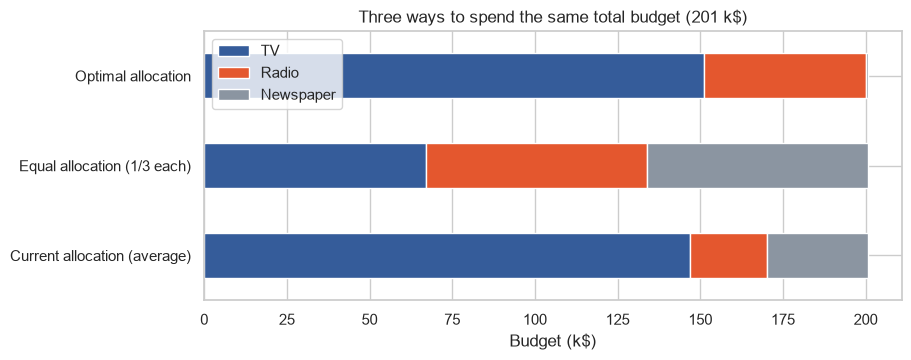

In [203]:
options[CHANNELS].plot.barh(stacked=True, figsize=(9, 3.5), color=[COLORS[c] for c in CHANNELS])
plt.xlabel("Budget (k$)")
plt.title(f"Three ways to spend the same total budget ({total:.0f} k$)")
plt.show()

**Interpretation**: with the same total budget, the optimal allocation **eliminates Newspaper** and **concentrates spend on TV and Radio**, substantially increasing sales. Radio reaches its **observed ceiling**: the model indicates it is underused, but **cannot tell us** what would happen beyond the observed range.

In [204]:
# How does the optimal allocation change as the total budget increases?
totals = np.arange(50, 351, 25)
rows = []
for t in totals:
    optimum = optimize_budget(final_model, t, CHANNELS, upper, step=1.0)
    scaled_current = {ch: base[ch] * t / total for ch in CHANNELS}  # same mix as current, scaled
    rows.append({**optimum["allocation"], "total": t, "optimal sales": optimum["predicted_sales"],
                 "current-mix sales": predict_sales(final_model, scaled_current)})
path = pd.DataFrame(rows).set_index("total")
path

,TV,Radio,Newspaper,optimal sales,current-mix sales
total,,,,,
50,29.0,21.0,0.0,7.897,7.252
75,40.0,35.0,0.0,9.737,8.398
100,52.0,48.0,0.0,11.877,9.583
125,76.0,49.0,0.0,14.119,10.807
150,101.0,49.0,0.0,16.222,12.070
175,126.0,49.0,0.0,18.187,13.371
200,151.0,49.0,0.0,20.014,14.711
225,176.0,49.0,0.0,21.702,16.091
250,201.0,49.0,0.0,23.253,17.509


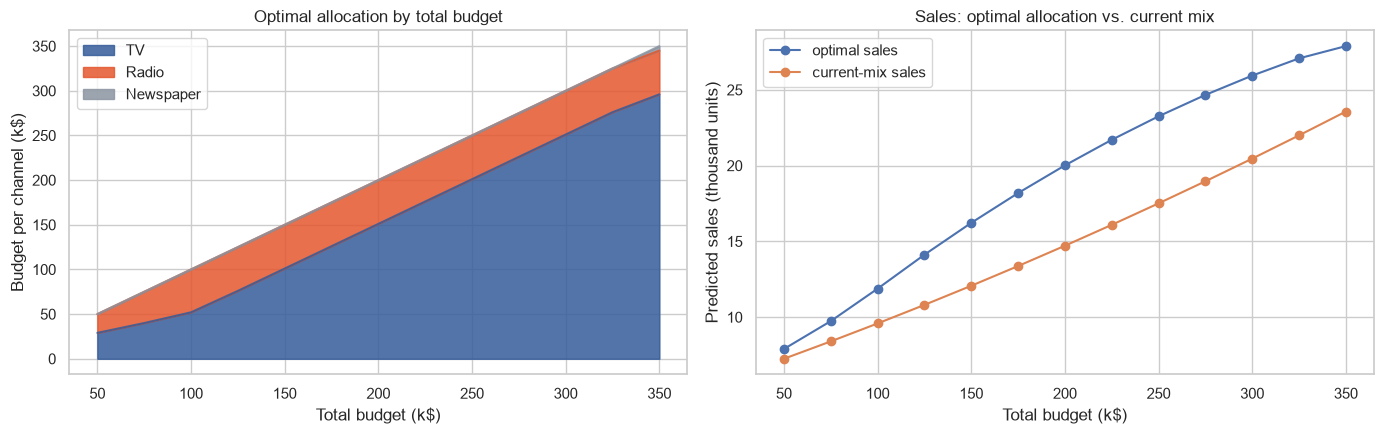

In [205]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
path[CHANNELS].plot.area(ax=axes[0], color=[COLORS[c] for c in CHANNELS], alpha=0.85)
axes[0].set(title="Optimal allocation by total budget", xlabel="Total budget (k$)", ylabel="Budget per channel (k$)")
path[["optimal sales", "current-mix sales"]].plot(ax=axes[1], marker="o")
axes[1].set(title="Sales: optimal allocation vs. current mix", xlabel="Total budget (k$)", ylabel="Predicted sales (thousand units)")
plt.tight_layout()
plt.show()

**Interpretation**: **Radio** gets priority: it reaches its **observed ceiling (≈ 49 k$) at a total budget of about 100 k$**. After that, **each additional dollar goes to TV**, up to its own ceiling. Newspaper appears (≈ 5 k$ at a 350 k$ budget) only because the entire budget must be spent somewhere; it adds no sales. The gap between the “optimal” allocation and the “current mix” is the **potential gain** from better allocation (about +4 to +6 thousand units over the 150–350 k$ range).

In [206]:
# Numerical summary generated automatically from the results above
gain = options.loc["Optimal allocation", "Gain vs. current"]
current_sales = options.loc["Current allocation (average)", "Predicted sales"]
print("SUMMARY FOR MARKETING LEADERSHIP")
print("-" * 60)
print(f"1. Model: test R² = {metrics(y_test, final_model.predict(X_test))['R²']:.3f}, typical error (RMSE) = {metrics(y_test, final_model.predict(X_test))['RMSE']:.2f} thousand units.")
print(f"2. At average budgets, an additional $1,000 generates: Radio ≈ {effects['Radio'] * 1000:.0f} units, TV ≈ {effects['TV'] * 1000:.0f} units, Newspaper ≈ {effects['Newspaper'] * 1000:.0f} units.")
print(f"3. Radio is {effects['Radio'] / effects['TV']:.1f}x more cost-effective than TV per dollar.")
print(f"4. Reallocate the average budget ({total:.0f} k$) as follows: " + ", ".join(f"{k} {v:.0f} k$" for k, v in best['allocation'].items()))
print(f"   → predicted sales {best['predicted_sales']:.1f} vs. {current_sales:.1f} today ({gain:+.1f} thousand units, {gain / current_sales * 100:+.0f}%), WITHOUT spending more.")

SUMMARY FOR MARKETING LEADERSHIP
------------------------------------------------------------
1. Model: test R² = 0.989, typical error (RMSE) = 0.60 thousand units.
2. At average budgets, an additional $1,000 generates: Radio ≈ 193 units, TV ≈ 44 units, Newspaper ≈ 0 units.
3. Radio is 4.4x more cost-effective than TV per dollar.
4. Reallocate the average budget (201 k$) as follows: TV 151 k$, Radio 49 k$, Newspaper 1 k$
   → predicted sales 20.0 vs. 14.8 today (+5.3 thousand units, +36%), WITHOUT spending more.


## Marketing recommendations

1. **Stop or sharply reduce newspaper spending.** No measurable effect (high p-value, no predictive gain, and raw correlation explained by Radio). Every dollar moved from Newspaper to another channel is a net gain.
2. **Increase Radio spend within the range supported by the data.** It is the most cost-effective channel per dollar and **amplifies** TV. Observed Radio budgets do not exceed ≈ 50 k$: beyond that, we lack data → **test gradually** (in stages) before rolling out more broadly.
3. **Keep TV as a supporting channel, but do not overallocate.** It is the main driver of sales volume, but has **diminishing returns**: beyond a certain level, the next dollar contributes little.
4. **Think in terms of a “mix,” not isolated channels.** TV and Radio reinforce each other: reducing one weakens the other. Use the API optimizer to allocate each annual budget.
5. **Validate through experimentation.** These results are **correlational**: a controlled test (by region or period) would confirm causality before a major change.

## Limitations to keep in mind

- Only **200 campaigns** and **no dates**: no seasonality, trend, or lagged effect (advertising can take weeks to have an impact); tracking data over time would enable deeper analysis.
- **Valid range**: forecasts beyond observed budgets (TV > 296 k$, Radio > 50 k$) are unreliable **extrapolations** (the API flags them).
- **Very low TV budgets**: when TV spend is near zero, the model overestimates sales (section 9); do not use it to simulate eliminating TV entirely.
- **Correlation ≠ causation**: the model describes observed associations, not proven effects.
- **No costs or margins**: we maximize *sales*, not *profit*.

## 13. Production deployment

Everything validated here is implemented as tested code in `src/sales_prediction/`:

| Notebook step | Production module |
|---|---|
| Cleaning (§3) | `data.py` |
| Feature engineering & pipeline (§9, §11) | `features.py` |
| Cross-validation and metrics (§6) | `evaluate.py` |
| Statistics, marginal effects, scenarios, optimization (§7, §12) | `analysis.py` |
| Training, quality gate, serialization | `train.py` |
| Loading and inference | `predict.py` |
| REST API + web interface | `api/` |

The next cell runs **production training** from the notebook (equivalent to `uv run sales-train`) and creates `models/model.joblib`.

In [207]:
from sales_prediction.train import train

metadata = train(config)  # writes models/model.joblib, models/metadata.json, and data/processed/
print("Model version:", metadata["model_version"])
print("Model columns:", metadata["engineered_columns"])
pd.DataFrame(metadata["metrics"]).T

Model version: 0.1.0-69104adc
Model columns: ['TV', 'Radio', 'TV_x_Radio', 'TV_sq']


,r2_mean,r2_std,rmse_mean,rmse_std,r2,rmse,mae
cross_validation,0.983,0.014,0.613,0.267,NaN,NaN,NaN
test,NaN,NaN,NaN,NaN,0.989,0.602,0.497


**Next step**: launch the API (`uv run uvicorn sales_prediction.api.main:create_app --factory --reload`), then containerize with Docker and deploy to Render (see `README.md`).